# L6 / E4 — W1 Equal Calibrated Weighting · K=3 · External evaluation

Standalone notebook. Regenerates **P1 word TF-IDF + P0 character TF-IDF + V1/N1/S2 engineered features** directly from redacted tweet text using modular GitHub code. **W1** calibrates all five blocks to equal 20% expected squared-distance contribution. Original sentiment labels are opened only in **Cell #9**, after saving cluster assignments. No L1–L5 generated data is loaded; no GitHub writes.


In [1]:
# 1 — Environment: install dependencies for GitHub source imports
%pip -q install emoji num2words wordninja wordfreq symspellpy "spacy>=3.7" "scikit-learn>=1.4" "scipy>=1.11" "vaderSentiment==3.3.2" "gensim>=4.3.3"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 541.6/541.6 kB 10.0 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.0/126.0 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 610.9/610.9 kB 14.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.5/163.5 kB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.8/56.8 MB 9.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 39.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 23.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 821.3 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.1/183.1 kB 4.1 MB/s eta 0:00:00


**Note:** Dependencies are installed explicitly to avoid remote relative-requirements resolution. Library versions and Git revision are recorded in the manifest. If installation fails, stop rather than silently altering the pipeline.

In [2]:
# 2 — Inputs and output destination. Change only these paths.
from pathlib import Path
from google.colab import drive
drive.mount('/content/drive')

INPUT_CSV = Path('/content/drive/MyDrive/MSI5001 project/EDA/Tweets-redacted.csv')
OUTPUT_DIR = Path('/content/drive/MyDrive/MSI5001 project/EDA/L6-externaleval/E4')
assert INPUT_CSV.is_file(), f'Missing redacted CSV: {INPUT_CSV}'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print('Input:', INPUT_CSV)
print('Output:', OUTPUT_DIR)


Mounted at /content/drive
Input: /content/drive/MyDrive/MSI5001 project/EDA/Tweets-redacted.csv
Output: /content/drive/MyDrive/MSI5001 project/EDA/L6-externaleval/E4


In [3]:
# 3 — Fresh GitHub source checkout; never import old generated matrices.
import subprocess
REPO_DIR = Path('/content/l6_source_code')
assert not REPO_DIR.exists(), 'Checkout already exists; use a fresh Colab runtime or remove it deliberately.'
subprocess.run(['git', 'clone', '--depth', '1', 'https://github.com/frankie-chew-nus/sentiment-clustering-ml.git', str(REPO_DIR)], check=True)
GIT_REVISION = subprocess.check_output(['git', '-C', str(REPO_DIR), 'rev-parse', 'HEAD'], text=True).strip()
import sys
sys.path.insert(0, str(REPO_DIR))
from preprocessing import preprocess_text
print('Git revision:', GIT_REVISION)


Git revision: e99f1072dd5a9d0b449bdd477eaa43219b32b007


In [4]:
# 4 — Read ONLY original tweet text. Never read labels in the clustering stage.
import pandas as pd, numpy as np, hashlib, json, platform, importlib.metadata as im

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for block in iter(lambda: f.read(1024*1024), b''):
            h.update(block)
    return h.hexdigest()

raw = pd.read_csv(INPUT_CSV, usecols=['text'], dtype={'text':'string'})
assert raw['text'].notna().all(), 'Null text found'
assert len(raw) == 14639, f'Unexpected corpus size: {len(raw)}'
source_row = np.arange(len(raw), dtype=np.int64)
texts = raw['text'].astype(str).tolist()
source_sha = sha256_file(INPUT_CSV)
text_digest = hashlib.sha256(json.dumps(texts, ensure_ascii=False).encode('utf-8')).hexdigest()
print('Rows:', len(texts), '| Source SHA256:', source_sha)
print('Text sequence SHA256:', text_digest)


Rows: 14639 | Source SHA256: a41aeefcff9740c090153f608691d345c84f59084e40f03169c2f667df66578e
Text sequence SHA256: 6f0a14893aeb25c33186bb5597c2ba683895d05a129b6ef62578c1732d8624b4


In [5]:
# 5 — Explicit modular P0- and P1-equivalent settings; no processed CSVs used.
# Both variants are built from the same ordered original tweets.
P0_CONFIG_EXPLICIT = {
    'decode_html_entities': True, 'remove_urls': True,
    'replace_airline_mentions': True, 'remove_other_mentions': True,
    'replace_airline_hashtags': True, 'replace_airline_names': True,
    'strip_hashtag_symbols': True,
    'hashtag_segmentation_mode': 'none',
    'hashtag_segmentation_min_token_length': 7,
    'expand_contractions': False, 'convert_numbers': False,
    'lowercase': False, 'punctuation_mode': 'keep', 'emoji_mode': 'keep',
    'segmentation_mode': 'none', 'correct_spelling': False,
    'lemmatize': False, 'remove_stopwords': False,
    'normalize_whitespace': True,
}
P1_CONFIG_EXPLICIT = {
    **P0_CONFIG_EXPLICIT,
    'expand_contractions': True,
    'lowercase': True,
    'emoji_mode': 'describe',
}
p0_texts = [preprocess_text(t, P0_CONFIG_EXPLICIT) for t in texts]
p1_texts = [preprocess_text(t, P1_CONFIG_EXPLICIT) for t in texts]
assert len(p0_texts) == len(p1_texts) == len(texts)
assert all(isinstance(t, str) and t.strip() for t in p0_texts)
assert all(isinstance(t, str) and t.strip() for t in p1_texts)
print('P0 and P1 generated from RAW:', len(texts), 'rows each, in source order')


P0 and P1 generated from RAW: 14639 rows each, in source order


In [6]:
# 6 — E4 / W1: fresh TF-IDF and engineered features, equal calibrated weighting.
# E4 uses five blocks in order: word, char, V, N, S.
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy import sparse
from feature_engineering import extract_vader_frame, extract_n_frame, extract_s_frame
from feature_scaling import EngineeredFeatureScaler
from feature_scaling_config import ScalingSpec
from feature_integration import BlockIntegrator, WeightingSpec

WORD_CONFIG = dict(analyzer='word', ngram_range=(1, 2), min_df=2,
                   max_df=0.95, max_features=30000, sublinear_tf=True,
                   norm='l2', use_idf=True, lowercase=False, dtype=np.float64)
CHAR_CONFIG = dict(analyzer='char', ngram_range=(3, 5), min_df=2,
                   max_df=0.95, max_features=50000, sublinear_tf=True,
                   norm='l2', use_idf=True, lowercase=False, dtype=np.float64)
word_vectorizer = TfidfVectorizer(**WORD_CONFIG)
char_vectorizer = TfidfVectorizer(**CHAR_CONFIG)
X_word = word_vectorizer.fit_transform(p1_texts).tocsr()
X_char = char_vectorizer.fit_transform(p0_texts).tocsr()

v_frame = extract_vader_frame(texts)      # RAW
n_frame = extract_n_frame(p1_texts)      # P1
s_frame = extract_s_frame(texts)        # RAW
assert all(np.array_equal(f['row_id'].to_numpy(), source_row)
           for f in (v_frame, n_frame, s_frame))
master = v_frame.merge(n_frame, on='row_id', validate='one_to_one', sort=False)
master = master.merge(s_frame, on='row_id', validate='one_to_one', sort=False)
assert np.array_equal(master['row_id'].to_numpy(), source_row)

SCALING_CONFIG = ScalingSpec(method='bounded', percentile=95.0,
                             positive_fallback=True, clip=True)
scaler = EngineeredFeatureScaler(variants=('V1', 'N1', 'S2'),
                                 spec=SCALING_CONFIG)
scaled = scaler.fit_transform(master)
# Approved order from feature_scaling_config: V_compound, N_negation_count,
# S_exclamation_count, S_uppercase_ratio.
assert tuple(scaler.columns) == ('V_compound', 'N_negation_count',
                                'S_exclamation_count', 'S_uppercase_ratio')
assert scaled.shape == (len(texts), 4)
blocks = {
    'word': X_word,
    'char': X_char,
    'V': scaled[:, 0:1],
    'N': scaled[:, 1:2],
    'S': scaled[:, 2:4],
}
integrator = BlockIntegrator(WeightingSpec(method='W1'))
X = integrator.fit_transform(blocks)
assert X.shape[0] == len(texts) and X.shape[1] == X_word.shape[1] + X_char.shape[1] + 4
assert np.isfinite(X.data).all()
assert all(np.isclose(v, 0.2, atol=1e-12) for v in integrator.targets_.values())
assert len(integrator.weights_) == 5
print('Word:', X_word.shape, '| Character:', X_char.shape)
print('Engineered:', scaled.shape, '| W1:', X.shape, '| NNZ:', X.nnz)
print('W1 target shares:', integrator.targets_)
print('W1 block weights:', integrator.weights_)


Word: (14639, 29792) | Character: (14639, 50000)
Engineered: (14639, 4) | W1: (14639, 79796) | NNZ: 3728386
W1 target shares: {'word': 0.2, 'char': 0.2, 'V': 0.2, 'N': 0.2, 'S': 0.2}
W1 block weights: {'word': 0.3182361468979772, 'char': 0.31959575543751884, 'V': 0.6673870262017859, 'N': 0.9267492010600089, 'S': 0.9484253363178086}


In [7]:
# 7 — K-means: labels are still unavailable to this stage.
from sklearn.cluster import KMeans
KMEANS_CONFIG = dict(n_clusters=3, init='k-means++', n_init=10,
                     max_iter=300, tol=1e-4, random_state=5001)
model = KMeans(**KMEANS_CONFIG)
clusters = model.fit_predict(X)
assert len(clusters) == len(source_row)
assert set(np.unique(clusters)) == {0,1,2}
print('Cluster sizes:', dict(zip(*np.unique(clusters, return_counts=True))))


Cluster sizes: {np.int32(0): np.int64(4317), np.int32(1): np.int64(7409), np.int32(2): np.int64(2913)}


In [8]:
# 8 — Freeze/save label-blind assignments BEFORE reading labels.
import datetime
import sklearn, scipy
versions = {k: im.version(k) for k in ['numpy','pandas','scikit-learn','scipy','emoji','vaderSentiment']}
def serializable_config(cfg):
    return {k: (list(v) if isinstance(v,tuple) else str(v) if isinstance(v,type) else v)
            for k,v in cfg.items()}
manifest = {
    'experiment':'E4', 'representation':'W1_equal_word_p1_char_p0_V1_N1_S2',
    'created_utc':datetime.datetime.now(datetime.timezone.utc).isoformat(),
    'git_revision':GIT_REVISION, 'source_csv':INPUT_CSV.name,
    'source_sha256':source_sha, 'text_sequence_sha256':text_digest,
    'rows':len(texts), 'row_alignment':'source_row=original CSV positional row; no sorting/filtering',
    'preprocess_config':{'P0':P0_CONFIG_EXPLICIT,'P1':P1_CONFIG_EXPLICIT},
    'tfidf_config':{'word':serializable_config(WORD_CONFIG),'char':serializable_config(CHAR_CONFIG)},
    'scaling':scaler.manifest(), 'integration':integrator.manifest(),
    'kmeans_config':KMEANS_CONFIG,
    'block_shapes':{name:list(block.shape) for name,block in blocks.items()},
    'matrix_shape':list(X.shape), 'matrix_nnz':int(X.nnz),
    'cluster_sizes':np.bincount(clusters,minlength=3).tolist(),
    'versions':versions, 'python':platform.python_version(),
}
assign_path = OUTPUT_DIR/'E4_seed5001_assignments.csv'
pd.DataFrame({'source_row':source_row,'cluster_id':clusters}).to_csv(assign_path,index=False)
manifest['assignments_sha256'] = sha256_file(assign_path)
(OUTPUT_DIR/'E4_manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
print('Frozen assignments:',assign_path)


Frozen assignments: /content/drive/MyDrive/MSI5001 project/EDA/L6-externaleval/E4/E4_seed5001_assignments.csv


In [9]:
# 9 — Labelled data is accessed ONLY in this cell, after clustering is saved.
# Enter the original labelled CSV path manually when ready to evaluate.
LABEL_CSV = Path('ENTER_LABELLED_CSV_PATH')
assert LABEL_CSV.is_file(), f'Labelled CSV not found: {LABEL_CSV}'
assert LABEL_CSV.resolve() != INPUT_CSV.resolve(), 'Labelled and clustering input must be separate files'

saved = pd.read_csv(assign_path)
assert np.array_equal(saved['source_row'].to_numpy(), np.arange(len(texts)))
assert np.array_equal(saved['cluster_id'].to_numpy(), clusters)
assert sha256_file(INPUT_CSV) == source_sha, 'Clustering input changed after fitting'

# Verify the source texts match exactly, row by row, BEFORE reading labels.
label_texts = pd.read_csv(LABEL_CSV, usecols=['text'], dtype={'text': 'string'})['text']
assert label_texts.notna().all(), 'Missing text in labelled source'
assert label_texts.astype(str).tolist() == texts, 'Labelled CSV tweet text/order does not match clustering input'

labels = pd.read_csv(LABEL_CSV, usecols=['airline_sentiment'],
                     dtype={'airline_sentiment': 'string'})['airline_sentiment']
assert len(labels) == len(clusters) and labels.notna().all()
assert set(labels.unique()) == {'negative', 'neutral', 'positive'}
y_true = labels.astype(str).to_numpy()
y_pred = saved['cluster_id'].to_numpy()
print('Exact tweet-text/order alignment verified; sentiment labels available for evaluation.')


Exact tweet-text/order alignment verified; sentiment labels available for evaluation.


In [10]:
# 10 — External metrics and per-class diagnostics (Hungarian one-to-one mapping).
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, precision_recall_fscore_support, accuracy_score
from scipy.optimize import linear_sum_assignment
CLASSES = ['negative','neutral','positive']
CONTINGENCY = pd.crosstab(pd.Series(y_pred,name='cluster_id'),pd.Series(y_true,name='sentiment'))
CONTINGENCY = CONTINGENCY.reindex(index=[0,1,2],columns=CLASSES,fill_value=0)
counts = CONTINGENCY.to_numpy()
ri,ci = linear_sum_assignment(-counts)
mapping = {int(r):CLASSES[int(c)] for r,c in zip(ri,ci)}
mapped = np.array([mapping[int(c)] for c in y_pred])
precision,recall,f1,support = precision_recall_fscore_support(y_true,mapped,labels=CLASSES,zero_division=0)
per_class = pd.DataFrame({'sentiment':CLASSES,'precision':precision,'recall':recall,'f1':f1,'support':support})
metrics = {
    'experiment':'E4','seed':5001,'n':len(y_true),
    'ari':float(adjusted_rand_score(y_true,y_pred)),
    'nmi':float(normalized_mutual_info_score(y_true,y_pred)),
    'purity':float(counts.max(axis=1).sum()/counts.sum()),
    'mapped_accuracy':float(accuracy_score(y_true,mapped)),
    'macro_f1':float(np.mean(f1)),
    'cluster_to_sentiment_mapping':mapping,
    'majority_class_baseline':float(max(np.unique(y_true,return_counts=True)[1])/len(y_true)),
}
composition = CONTINGENCY.div(CONTINGENCY.sum(axis=1),axis=0)
print('External metrics:', metrics)
display(CONTINGENCY, composition, per_class)


External metrics: {'experiment': 'E4', 'seed': 5001, 'n': 14639, 'ari': 0.052099253455328245, 'nmi': 0.09569168428409688, 'purity': 0.6269553931279459, 'mapped_accuracy': 0.49197349545734, 'macro_f1': 0.4795288058045392, 'cluster_to_sentiment_mapping': {0: 'negative', 1: 'neutral', 2: 'positive'}, 'majority_class_baseline': 0.6269553931279459}


sentiment,negative,neutral,positive
cluster_id,,,
0,3755,417,145
1,4139,2250,1020
2,1284,432,1197


sentiment,negative,neutral,positive
cluster_id,,,
0,0.869817,0.096595,0.033588
1,0.558645,0.303685,0.137670
2,0.440783,0.148301,0.410917


,sentiment,precision,recall,f1,support
0,negative,0.869817,0.409131,0.556502,9178
1,neutral,0.303685,0.726041,0.428245,3099
2,positive,0.410917,0.506774,0.453839,2362


In [11]:
# 11 — Sampled silhouette; fixed label-blind sample, matching L5 sample size.
from sklearn.metrics import silhouette_score
rng = np.random.default_rng(5001)
sample_rows = np.sort(rng.choice(len(clusters),size=min(2000,len(clusters)),replace=False))
assert len(np.unique(clusters[sample_rows])) >= 2
metrics['silhouette_2000'] = float(silhouette_score(X[sample_rows],clusters[sample_rows],metric='euclidean'))
metrics['silhouette_sample_seed'] = 5001
metrics['silhouette_sample_size'] = len(sample_rows)
print('Sampled silhouette:', metrics['silhouette_2000'])


Sampled silhouette: 0.2272580981134104


In [12]:
# 12 — Save numerical evidence; no GitHub writes.
CONTINGENCY.to_csv(OUTPUT_DIR/'E4_contingency.csv')
composition.to_csv(OUTPUT_DIR/'E4_sentiment_composition.csv')
per_class.to_csv(OUTPUT_DIR/'E4_per_class_metrics.csv',index=False)
pd.DataFrame({'source_row':source_row,'cluster_id':y_pred,'mapped_sentiment':mapped,'true_sentiment':y_true}).to_csv(OUTPUT_DIR/'E4_evaluation_rows.csv',index=False)
(OUTPUT_DIR/'E4_metrics.json').write_text(json.dumps(metrics,indent=2),encoding='utf-8')
print('Saved E4 evaluation evidence to:', OUTPUT_DIR)
print('Review E4 outputs before proceeding. No files were committed to GitHub.')


Saved E4 evaluation evidence to: /content/drive/MyDrive/MSI5001 project/EDA/L6-externaleval/E4
Review E4 outputs before proceeding. No files were committed to GitHub.


## Understanding the Evaluation Results

The objective is to determine whether the K-means clusters correspond to the original **negative, neutral and positive** sentiment labels.

### 1. Overall evaluation metrics

| Metric | What it measures | High score | Low score |
|---|---|---|---|
| **Adjusted Rand Index (ARI)** | Agreement between clusters and true sentiment classes, adjusted for chance | Near 1: strong agreement | Near 0: chance-level; negative: worse than chance |
| **Normalized Mutual Information (NMI)** | Information shared between clusters and sentiment classes | Near 1: strong association | Near 0: little association |
| **Cluster Purity** | Proportion belonging to the dominant sentiment within each cluster | Clusters are more homogeneous | Clusters contain mixed sentiments |
| **Optimally Mapped Accuracy** | Correct matches after one-to-one cluster-to-sentiment assignment | More tweets correctly matched | More sentiment mismatches |
| **Macro F1** | Average F1 across negative, neutral and positive, with equal class weighting | Better balanced sentiment recovery | One or more classes poorly recovered |
| **Silhouette** | How compact and separated the clusters are in feature space | Higher: stronger geometric separation | Near 0: overlapping clusters; negative: possible misassignment |

**Important:** Higher scores are generally preferable, but silhouette does not measure sentiment correctness. The original dataset is approximately 62.7% negative, so purity and mapped accuracy require careful interpretation.

### 2. Sentiment composition by cluster

The stacked bar chart shows the percentage of negative, neutral and positive tweets in each cluster.

**What to look for:** Ideally, the three clusters should each be dominated by a different sentiment class. If all clusters are mostly negative, the representation is not clearly distinguishing all three sentiments.

### 3. Contingency matrix (heatmap)

The heatmap shows the actual number of negative, neutral and positive tweets in each cluster.

**What to look for:** Large counts concentrated in three different sentiment columns, after allowing cluster rows to be reordered. Cluster IDs 0, 1 and 2 are arbitrary and do not inherently represent negative, neutral or positive.

### 4. Per-class precision, recall and F1

- **Precision:** Of tweets mapped to a particular sentiment, how many truly belong to that sentiment? Higher means fewer false positives.
- **Recall:** Of all tweets with a particular true sentiment, how many were recovered? Higher means fewer missed cases.
- **F1-score:** Balances precision and recall for each sentiment class.
- **Macro F1:** The average of all three class F1-scores, giving negative, neutral and positive equal importance.

**What to look for:** Whether all three sentiments are recovered reasonably well, rather than achieving good results only for the majority negative class.

### 5. Overall interpretation

For L6, **ARI and NMI are the principal external evaluation metrics**. Macro F1 and per-class results help identify weaknesses in sentiment recovery. Purity and mapped accuracy provide more intuitive measures, while the contingency matrix and composition chart explain how the clusters are distributed.

Silhouette measures internal separation only. A representation can produce well-separated clusters without successfully recovering sentiment classes.

All results describe clustering of the current corpus, not classification accuracy on unseen tweets. Avoid interpreting arbitrary score thresholds as universal definitions of good or poor performance.

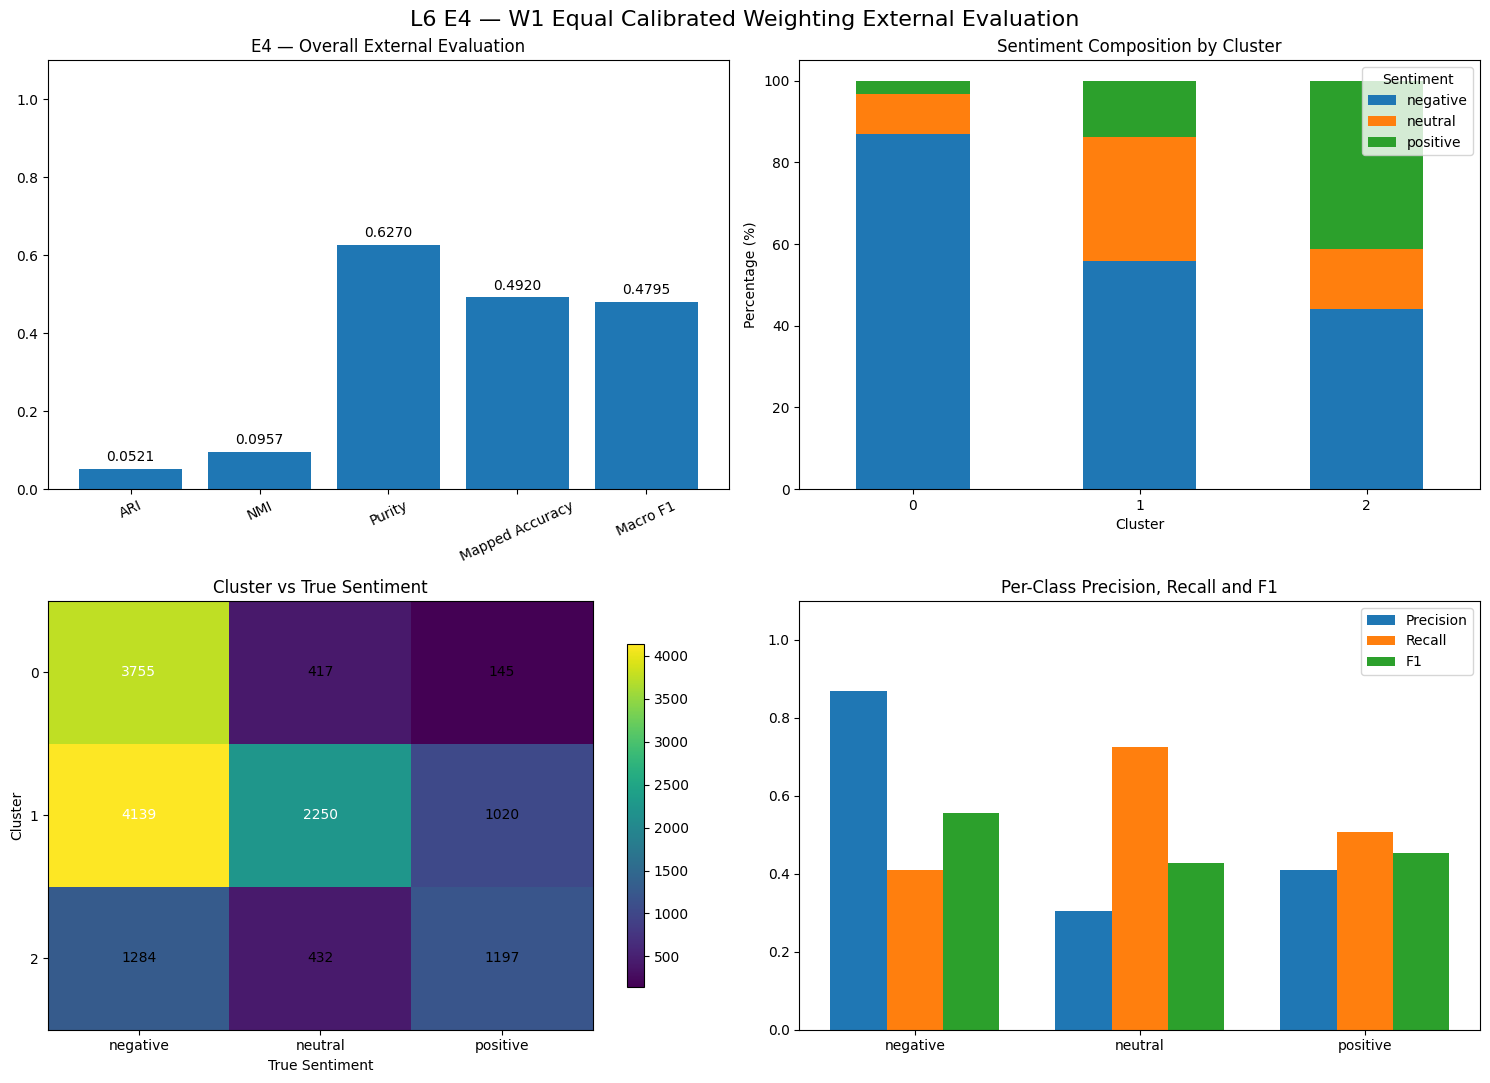


External Evaluation Summary
----------------------------------------
ARI:             0.052099
NMI:             0.095692
Purity:          0.626955
Mapped Accuracy: 0.491973
Macro F1:        0.479529

Cluster-to-sentiment mapping:
{np.int64(0): 'negative', np.int64(1): 'neutral', np.int64(2): 'positive'}

Per-class performance:


,Sentiment,Precision,Recall,F1,Support
0,negative,0.869817,0.409131,0.556502,9178
1,neutral,0.303685,0.726041,0.428245,3099
2,positive,0.410917,0.506774,0.453839,2362



Figure saved to: /content/drive/MyDrive/MSI5001 project/EDA/L6-externaleval/E4/figures/E4_external_evaluation.png


In [13]:
# L6 E4 — External Evaluation Visualizations (Updated)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment
from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score,
    precision_recall_fscore_support
)

# Existing notebook variables
y_true = np.asarray(labels)
cluster_labels = np.asarray(y_pred)

classes = ["negative", "neutral", "positive"]
clusters = sorted(np.unique(cluster_labels))

assert len(y_true) == len(cluster_labels) == 14639
assert set(np.unique(y_true)) == set(classes)
assert len(clusters) == 3

# Contingency matrix
ct = pd.crosstab(
    pd.Series(cluster_labels, name="Cluster"),
    pd.Series(y_true, name="Sentiment")
).reindex(index=clusters, columns=classes, fill_value=0)

# Optimal one-to-one cluster-to-sentiment mapping
rows, cols = linear_sum_assignment(-ct.to_numpy())

mapping = {
    ct.index[r]: ct.columns[c]
    for r, c in zip(rows, cols)
}

y_mapped = np.array([mapping[c] for c in cluster_labels])

# Evaluation metrics
ari = adjusted_rand_score(y_true, cluster_labels)
nmi = normalized_mutual_info_score(y_true, cluster_labels)
purity = ct.max(axis=1).sum() / ct.to_numpy().sum()
accuracy = np.mean(y_mapped == y_true)

precision, recall, f1, support = precision_recall_fscore_support(
    y_true,
    y_mapped,
    labels=classes,
    zero_division=0
)

macro_f1 = float(np.mean(f1))

# Four visualization panels
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# 1. Overall metrics, including Macro F1
metric_names = [
    "ARI", "NMI", "Purity",
    "Mapped Accuracy", "Macro F1"
]
metric_values = [ari, nmi, purity, accuracy, macro_f1]

bars = axes[0, 0].bar(metric_names, metric_values)
axes[0, 0].set_title("E4 — Overall External Evaluation")
axes[0, 0].set_ylim(0, 1.1)
axes[0, 0].tick_params(axis="x", rotation=25)

for bar, value in zip(bars, metric_values):
    axes[0, 0].text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.02,
        f"{value:.4f}",
        ha="center"
    )

# 2. Sentiment composition
composition = ct.div(ct.sum(axis=1), axis=0) * 100

composition.plot(
    kind="bar",
    stacked=True,
    ax=axes[0, 1]
)

axes[0, 1].set_title("Sentiment Composition by Cluster")
axes[0, 1].set_ylabel("Percentage (%)")
axes[0, 1].set_xlabel("Cluster")
axes[0, 1].tick_params(axis="x", rotation=0)
axes[0, 1].legend(title="Sentiment")

# 3. Contingency matrix
im = axes[1, 0].imshow(ct.to_numpy(), aspect="auto")
axes[1, 0].set_title("Cluster vs True Sentiment")
axes[1, 0].set_xticks(range(len(classes)), classes)
axes[1, 0].set_yticks(range(len(clusters)), clusters)
axes[1, 0].set_xlabel("True Sentiment")
axes[1, 0].set_ylabel("Cluster")

for i in range(len(clusters)):
    for j in range(len(classes)):
        value = ct.iloc[i, j]
        axes[1, 0].text(
            j, i, str(value),
            ha="center",
            va="center",
            color="white" if value > ct.to_numpy().max()/2
            else "black"
        )

fig.colorbar(im, ax=axes[1, 0], shrink=0.8)

# 4. Per-class Precision, Recall and F1
x = np.arange(len(classes))
width = 0.25

axes[1, 1].bar(x-width, precision, width, label="Precision")
axes[1, 1].bar(x, recall, width, label="Recall")
axes[1, 1].bar(x+width, f1, width, label="F1")

axes[1, 1].set_xticks(x, classes)
axes[1, 1].set_ylim(0, 1.1)
axes[1, 1].set_title("Per-Class Precision, Recall and F1")
axes[1, 1].legend()

fig.suptitle(
    "L6 E4 — W1 Equal Calibrated Weighting External Evaluation",
    fontsize=16
)

plt.tight_layout()

# Save figure
figure_dir = OUTPUT_DIR / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)

figure_path = figure_dir / "E4_external_evaluation.png"
fig.savefig(figure_path, dpi=200, bbox_inches="tight")
plt.show()

# Numerical summary
print("\nExternal Evaluation Summary")
print("-" * 40)
print(f"ARI:             {ari:.6f}")
print(f"NMI:             {nmi:.6f}")
print(f"Purity:          {purity:.6f}")
print(f"Mapped Accuracy: {accuracy:.6f}")
print(f"Macro F1:        {macro_f1:.6f}")

print("\nCluster-to-sentiment mapping:")
print(mapping)

print("\nPer-class performance:")
display(pd.DataFrame({
    "Sentiment": classes,
    "Precision": precision,
    "Recall": recall,
    "F1": f1,
    "Support": support
}))

print("\nFigure saved to:", figure_path)